# Numerical final selection

Builds a decision table for all numerical variables with scores, correlations, automatic suggestions,
and your decisions. The variables marked to keep drive the city stability check, profile, and plots.

**Project step:** §4.2 step 1.0.

**Inputs:** `outputs/03_phase_01_feature_selection_numerical{suffix}.csv`,
`outputs/04_phase_01_correlations_numerical{suffix}.csv`, and `data/master_listing.parquet`.

**Outputs:** `outputs/05_phase_01_numerical_decision_table{suffix}.csv`,
`outputs/05_phase_01_numerical_profile{suffix}.csv`,
`outputs/05_phase_01_numerical_gini_by_city{suffix}.csv`,
`outputs/05_phase_01_numerical_histograms{suffix}.png`, and
`outputs/05_phase_01_numerical_target_by_decile{suffix}.png`.

**Run after:** 04_numerical_correlations.

**Runtime:** ~5 min.

In [1]:
# ---- Data ----
INPUT = "data/master_listing.parquet"   # relative to the repo root
OUTPUT_DIR = "outputs"                  # every CSV / XLSX / PNG goes here

# ---- Filters (None = no filter) ----
CITY = None             # "chicago", "dfw", "dc", or a list of them       -> column `market`
NEIGHBORHOOD = None     # submarket or list -> `market_building__submarket`
START_DATE = None       # "YYYY-MM-DD": keep listings with DATE_COLUMN >= START_DATE
END_DATE = None         # "YYYY-MM-DD": keep listings with DATE_COLUMN <= END_DATE
DATE_COLUMN = "market_unit__enter_market"

# ---- Selection ----
MIN_COMPLETENESS = 50
MIN_METHODS = 2
GINI_MIN = 0.10
GB_MIN = 0.001
REDUNDANT = 0.9
METHOD = "spearman"
TARGET = "market_price_observation__first_asking_rent"
ANSWER_KEY = "truth_floorplan_market_rent__true_market_rent_at_enter"

DECISIONS = "notebooks/phase_01_market_rent/numerical_decisions.csv"   # edited by hand; never overwritten

In [2]:
from pathlib import Path

import pandas as pd

BLUE, GREEN, YELLOW, RED, BOLD, RESET = "\033[94m", "\033[92m", "\033[93m", "\033[91m", "\033[1m", "\033[0m"


def step(msg):
    print(f"\n{BOLD}{BLUE}▶ {msg}{RESET}")


def done(msg):
    print(f"{GREEN}  ✓ {msg}{RESET}")


def note(msg):
    print(f"{YELLOW}  • {msg}{RESET}")


ROOT = Path.cwd()
while not (ROOT / "data" / "master_listing.parquet").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
MASTER = ROOT / INPUT
CATALOG = ROOT / "data" / "master_columns.csv"
OUTPUTS = ROOT / OUTPUT_DIR
OUTPUTS.mkdir(parents=True, exist_ok=True)
NN = 5
FILTER_COLUMNS = ["market", "market_building__submarket", DATE_COLUMN]


def _as_list(value):
    """Normalize one filter value or a list of values."""
    if value is None:
        return None
    return [value] if isinstance(value, str) else list(value)


def suffix():
    """Build the shared output suffix from the active filters."""
    parts = []
    if CITY is not None:
        parts.append("+".join(map(str, _as_list(CITY))))
    if NEIGHBORHOOD is not None:
        parts.append("+".join(map(str, _as_list(NEIGHBORHOOD))))
    if START_DATE is not None or END_DATE is not None:
        parts.append(f"{START_DATE or 'start'}_to_{END_DATE or 'end'}")
    return "" if not parts else "__" + "__".join(parts)


def out(name, ext="csv"):
    """Build an output path with this notebook's number and active filters."""
    return OUTPUTS / f"{NN:02d}_phase_01_{name}{suffix()}.{ext}"


def upstream(number, name, ext="csv"):
    """Build an upstream notebook's output path with the active filters."""
    return OUTPUTS / f"{number:02d}_phase_01_{name}{suffix()}.{ext}"


def need(path, notebook):
    """Raise a clear instruction when a required upstream output is missing."""
    if not Path(path).exists():
        raise FileNotFoundError(f"Run {notebook} first; missing {path}")


def load(columns):
    """Read requested master columns and apply the configured listing filters."""
    requested = list(dict.fromkeys(columns))
    read_columns = list(dict.fromkeys(requested + FILTER_COLUMNS))
    frame = pd.read_parquet(MASTER, columns=read_columns)
    valid_values = {
        column: sorted(frame[column].dropna().astype(str).unique())
        for column in ("market", "market_building__submarket")
    }
    for column, value, label in (
        ("market", CITY, "city"),
        ("market_building__submarket", NEIGHBORHOOD, "neighborhood"),
    ):
        if value is not None:
            wanted = list(map(str, _as_list(value)))
            valid = valid_values[column]
            unknown = sorted(set(wanted) - set(valid))
            if unknown:
                raise ValueError(f"Unknown {label}(s) {unknown}. Valid values: {valid}")
            before = len(frame)
            frame = frame[frame[column].astype(str).isin(wanted)]
            note(f"{label}: {before:,} → {len(frame):,} rows")
    if START_DATE is not None:
        before = len(frame)
        frame = frame[frame[DATE_COLUMN] >= pd.Timestamp(START_DATE)]
        note(f"start date: {before:,} → {len(frame):,} rows")
    if END_DATE is not None:
        before = len(frame)
        frame = frame[frame[DATE_COLUMN] <= pd.Timestamp(END_DATE)]
        note(f"end date: {before:,} → {len(frame):,} rows")
    return frame[requested]


## Decisions and redundancy

The decision table includes every numerical variable. The suggested decision drops variables whose
`x_status` is not `candidate`, then applies completeness, multi-method support, and redundancy rules
to the remaining candidates. Correlations use pairwise-complete filtered rows. Edit
`notebooks/phase_01_market_rent/numerical_decisions.csv` to override suggestions: enter `keep` or
`drop` in `my_decision` and optionally add a comment. Notebook 05 creates this file when it is missing
and never overwrites it.

In [3]:
import math

import matplotlib.pyplot as plt
import numpy as np

SELECTION_PATH = upstream(3, "feature_selection_numerical")
CORRELATION_PATH = upstream(4, "correlations_numerical")
need(SELECTION_PATH, "03_feature_selection_numerical")
need(CORRELATION_PATH, "04_numerical_correlations")
step(f"Reading {SELECTION_PATH.relative_to(ROOT)}")
selection = pd.read_csv(SELECTION_PATH)
done(f"{len(selection)} numerical variables")
features = selection.loc[selection["feature"].ne(TARGET), "feature"].tolist()
frame = load(features + [TARGET, "market"])
correlation_matrix = pd.read_csv(CORRELATION_PATH, index_col="variable")


def gini(x, y):
    """Normalized Gini of ordering y by x.

    Sort by x from high to low, take the Gini of the Lorenz curve of cumulative y, and divide by
    the Gini of the perfect ordering (y by itself). Tied x values are taken as one block, so a
    feature with few distinct values (bed, bath) is not scored on an arbitrary tie order.
    """
    def lorenz_gini(key):
        g = pd.DataFrame({"k": key, "y": y}).groupby("k")["y"].agg(["size", "sum"]).iloc[::-1]
        px = np.r_[0, g["size"].cumsum() / len(y)]
        py = np.r_[0, g["sum"].cumsum() / y.sum()]
        return 2 * ((py[1:] + py[:-1]) / 2 * np.diff(px)).sum() - 1
    return lorenz_gini(x) / lorenz_gini(y)


step(f"Correlating each numerical variable with {TARGET}")
corr_rows = []
for feature in features:
    pair = frame[[feature, TARGET]].dropna()
    corr_rows.append({
        "feature": feature,
        "corr_with_target": pair[feature].corr(pair[TARGET], method=METHOD),
        "n_with_target": len(pair),
    })
target_correlations = pd.DataFrame(corr_rows)

matrix_correlations = []
for feature in selection["feature"]:
    if feature not in correlation_matrix.index:
        continue
    values = correlation_matrix.loc[feature].drop(labels=[feature], errors="ignore").dropna()
    if values.empty:
        continue
    related = values.abs().idxmax()
    matrix_correlations.append({
        "feature": feature,
        "most_correlated_with": related,
        "most_correlated_rho": values[related],
    })
most_correlated = pd.DataFrame(
    matrix_correlations,
    columns=["feature", "most_correlated_with", "most_correlated_rho"],
)

selection["n_methods"] = (
    (selection["gini"].abs() >= GINI_MIN).astype(int)
    + (selection["gradient_boosting"] > GB_MIN).astype(int)
    + (selection["lasso"].fillna(0) != 0).astype(int)
)
selection["redundant_with"] = ""
selection["suggested"] = "drop"
selection["suggested_reason"] = selection["x_status"]
selection["note"] = ""
look_ahead_features = [
    "market_building__avg_price_change",
    "market_building__count_prices",
    "market_building__avg_price_duration_days",
    "market_building__avg_time_on_market_days",
]
look_ahead_note = "building-level average over the whole history; in a backtest it includes the future"
selection.loc[selection["feature"].isin(look_ahead_features), "note"] = look_ahead_note

step("Applying completeness and multi-method rules to candidates")
is_candidate = selection["x_status"].eq("candidate")
complete_enough = is_candidate & (selection["completeness_pct"] > MIN_COMPLETENESS)
methods_enough = selection["n_methods"] >= MIN_METHODS
selection.loc[complete_enough, ["suggested", "suggested_reason"]] = ["keep", "keep"]
for row_index, row in selection[is_candidate].iterrows():
    if row["completeness_pct"] <= MIN_COMPLETENESS:
        reason = f"drop: completeness {row['completeness_pct']:.1f}% <= {MIN_COMPLETENESS}%"
        selection.loc[row_index, ["suggested", "suggested_reason"]] = ["drop", reason]
    elif row["n_methods"] < MIN_METHODS:
        reason = f"drop: kept by {row['n_methods']} of 3 methods"
        selection.loc[row_index, ["suggested", "suggested_reason"]] = ["drop", reason]
survivors = set(selection.loc[selection["suggested"].eq("keep"), "feature"])
done(f"{len(survivors)} candidates pass both rules")

step(f"Checking redundancy among {len(survivors)} survivors with {METHOD}")
ordered_survivors = sorted(survivors)
correlations = frame[ordered_survivors].corr(method=METHOD, min_periods=2)
importance = selection.set_index("feature")["gradient_boosting"]
pairs = []
for first_index, first in enumerate(ordered_survivors):
    for second in ordered_survivors[first_index + 1:]:
        value = correlations.loc[first, second]
        if pd.notna(value) and abs(value) >= REDUNDANT:
            pairs.append((float(value), first, second))
pairs.sort(key=lambda pair: abs(pair[0]), reverse=True)
for correlation, first, second in pairs:
    if first not in survivors or second not in survivors:
        continue
    if importance[first] < importance[second]:
        dropped, kept = first, second
    else:
        dropped, kept = second, first
    survivors.remove(dropped)
    row_index = selection.index[selection["feature"].eq(dropped)][0]
    reason = (f"drop: redundant with {kept} (rho={correlation:+.2f}), "
              "lower GB importance")
    selection.loc[row_index, ["suggested", "suggested_reason", "redundant_with"]] = [
        "drop", reason, kept
    ]
    print(f"{RED}  ✗ {dropped} (rho={correlation:+.2f}); kept {kept}{RESET}")

DECISIONS_PATH = ROOT / DECISIONS
DECISION_COLUMNS = ["feature", "my_decision", "comment"]
if not DECISIONS_PATH.exists():
    decision_input = pd.DataFrame({
        "feature": selection.loc[selection["feature"].ne(TARGET), "feature"],
        "my_decision": "",
        "comment": "",
    })
    DECISIONS_PATH.parent.mkdir(parents=True, exist_ok=True)
    decision_input.to_csv(DECISIONS_PATH, index=False)
    note(f"Created {DECISIONS_PATH.relative_to(ROOT)}; fill my_decision with keep or drop.")
else:
    decision_input = pd.read_csv(DECISIONS_PATH, dtype=str).fillna("")
    missing_columns = set(DECISION_COLUMNS) - set(decision_input.columns)
    if missing_columns:
        raise ValueError(f"{DECISIONS_PATH} is missing columns: {sorted(missing_columns)}")

decision_input = decision_input[DECISION_COLUMNS].copy()
decision_input["feature"] = decision_input["feature"].astype(str).str.strip()
decision_input["my_decision"] = decision_input["my_decision"].astype(str).str.strip().str.lower()
bad_decisions = decision_input.loc[
    ~decision_input["my_decision"].isin(["", "keep", "drop"]), ["feature", "my_decision"]
]
if not bad_decisions.empty:
    bad_rows = [f"{row.feature}: {row.my_decision}" for row in bad_decisions.itertuples()]
    raise ValueError("Invalid my_decision values (use keep, drop, or blank): " + "; ".join(bad_rows))

numerical_features = set(selection.loc[selection["feature"].ne(TARGET), "feature"])
missing_decisions = sorted(numerical_features - set(decision_input["feature"]))
if missing_decisions:
    note(f"No decision-file row for {len(missing_decisions)} variable(s); treating as empty: "
         f"{', '.join(missing_decisions)}")
decision_input = decision_input.drop_duplicates("feature", keep="last").set_index("feature")
selection["my_decision"] = selection["feature"].map(decision_input["my_decision"]).fillna("")
selection["comment"] = selection["feature"].map(decision_input["comment"]).fillna("")
if selection.loc[selection["feature"].eq(TARGET), "my_decision"].eq("keep").any():
    print(f"{RED}  ⚠ TARGET cannot be kept; treating its decision as drop.{RESET}")
    selection.loc[selection["feature"].eq(TARGET), "my_decision"] = "drop"
selection["final_decision"] = selection["my_decision"].where(
    selection["my_decision"].ne(""), selection["suggested"]
)
selection["decided_by"] = np.where(selection["my_decision"].ne(""), "you", "suggested")

selection = selection.merge(target_correlations, on="feature", how="left")
selection = selection.merge(most_correlated, on="feature", how="left")
final = selection[selection["final_decision"].eq("keep")].copy()
output_columns = [
    "source_table", "feature", "completeness_pct", "role", "x_status", "gini",
    "gradient_boosting", "lasso", "gini_answer_key", "corr_with_target", "n_with_target",
    "most_correlated_with", "most_correlated_rho", "n_methods", "redundant_with", "note",
    "suggested", "suggested_reason", "my_decision", "comment", "final_decision", "decided_by",
]
decision_table = selection[output_columns].copy()
decision_table["_decision_order"] = decision_table["final_decision"].map({"keep": 0, "drop": 1})
decision_table = (decision_table.sort_values(
    ["_decision_order", "gradient_boosting"], ascending=[True, False], na_position="last"
).drop(columns="_decision_order").reset_index(drop=True))
decision_table.to_csv(out("numerical_decision_table"), index=False)
done(f"Wrote {len(decision_table)} decisions to {out('numerical_decision_table').name}")
decision_table


▶ Reading outputs/03_phase_01_feature_selection_numerical.csv
  ✓ 108 numerical variables



▶ Correlating each numerical variable with market_price_observation__first_asking_rent


/Users/vivianaseleniahanampa/Columbia/Fall 2026/Capstone Project Cod/From-Listings-to-Intelligence/.venv/lib/python3.11/site-packages/pandas/core/nanops.py:1673: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  return spearmanr(a, b)[0]



▶ Applying completeness and multi-method rules to candidates
  ✓ 4 candidates pass both rules

▶ Checking redundancy among 4 survivors with spearman


  • Created notebooks/phase_01_market_rent/numerical_decisions.csv; fill my_decision with keep or drop.
  ✓ Wrote 108 decisions to 05_phase_01_numerical_decision_table.csv


,source_table,feature,completeness_pct,role,x_status,gini,gradient_boosting,lasso,gini_answer_key,corr_with_target,...,most_correlated_rho,n_methods,redundant_with,note,suggested,suggested_reason,my_decision,comment,final_decision,decided_by
0,market_unit,market_unit__sqft,95.67,feature,candidate,0.5376,0.0021,0.44,0.5425,0.513370,...,0.9229,3,,,keep,keep,,,keep,suggested
1,market_building,market_building__avg_price_duration_days,100.00,feature,candidate,-0.2267,0.0001,-0.12,-0.2269,-0.233406,...,-0.7148,2,,building-level average over the whole history;...,keep,keep,,,keep,suggested
2,market_leasing_activity_daily,market_leasing_activity_daily__exposure_pct_at...,90.49,feature,candidate,-0.1115,0.0000,0.97,-0.1125,-0.115644,...,-0.7600,2,,,keep,keep,,,keep,suggested
3,market_building,market_building__avg_price_change,100.00,feature,candidate,-0.1244,0.0000,-1.45,-0.1261,-0.113123,...,0.3109,2,,building-level average over the whole history;...,keep,keep,,,keep,suggested
4,market_price_observation,market_price_observation__max_asking_rent,99.96,leaky,excluded: role leaky,0.9988,0.4992,330.70,0.9916,0.998717,...,0.9989,3,,,drop,excluded: role leaky,,,drop,suggested
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
103,market_building,market_building__main_entrance_quality_score,0.00,feature,excluded: empty,NaN,NaN,NaN,NaN,NaN,...,NaN,0,,,drop,excluded: empty,,,drop,suggested
104,market_building,market_building__stairs_hallway_quality_score,0.00,feature,excluded: empty,NaN,NaN,NaN,NaN,NaN,...,NaN,0,,,drop,excluded: empty,,,drop,suggested
105,market_building,market_building__swimming_pool_quality_score,0.00,feature,excluded: empty,NaN,NaN,NaN,NaN,NaN,...,NaN,0,,,drop,excluded: empty,,,drop,suggested
106,market_building,market_building__walk_in_closet_quality_score,0.00,feature,excluded: empty,NaN,NaN,NaN,NaN,NaN,...,NaN,0,,,drop,excluded: empty,,,drop,suggested


## City stability and feature profile

For each retained feature, Gini is calculated within each city. `max_minus_min` is the difference between its largest and smallest city Gini; a large spread means the feature works differently by city.

In [4]:
step("Gini by city")
cities = sorted(frame["market"].dropna().unique())
city_results = []
for feature in final["feature"]:
    row = {"feature": feature}
    values = []
    for city in cities:
        city_frame = frame[frame["market"].eq(city)]
        present = city_frame[feature].notna() & city_frame[TARGET].notna()
        value = gini(city_frame.loc[present, feature].to_numpy(),
                     city_frame.loc[present, TARGET].to_numpy())
        row[city] = value
        values.append(value)
    finite_values = [value for value in values if np.isfinite(value)]
    row["max_minus_min"] = max(finite_values) - min(finite_values) if finite_values else np.nan
    city_results.append(row)
gini_by_city = pd.DataFrame(city_results, columns=["feature"] + cities + ["max_minus_min"])
gini_by_city.round(4).to_csv(out("numerical_gini_by_city"), index=False)
done(f"Wrote {len(gini_by_city)} feature rows")
gini_by_city.round(4)

step("Profiling retained features")
profile_rows = []
for feature in final["feature"]:
    values = frame[feature].dropna()
    q1 = values.quantile(0.25)
    q3 = values.quantile(0.75)
    spread = q3 - q1
    outlier_mask = (values < q1 - 1.5 * spread) | (values > q3 + 1.5 * spread)
    profile_rows.append({
        "feature": feature,
        "n": len(values),
        "missing_pct": frame[feature].isna().mean() * 100,
        "mean": values.mean(),
        "std": values.std(),
        "min": values.min(),
        "p01": values.quantile(0.01),
        "p25": q1,
        "median": values.median(),
        "p75": q3,
        "p99": values.quantile(0.99),
        "max": values.max(),
        "skew": values.skew(),
        "outlier_pct": outlier_mask.mean() * 100,
    })
profile_columns = ["feature", "n", "missing_pct", "mean", "std", "min", "p01", "p25",
                   "median", "p75", "p99", "max", "skew", "outlier_pct"]
profile = pd.DataFrame(profile_rows, columns=profile_columns)
profile.to_csv(out("numerical_profile"), index=False)
done(f"Wrote {len(profile)} feature profiles")
profile.round(3)



▶ Gini by city


  ✓ Wrote 4 feature rows

▶ Profiling retained features


  ✓ Wrote 4 feature profiles


,feature,n,missing_pct,mean,std,min,p01,p25,median,p75,p99,max,skew,outlier_pct
0,market_unit__sqft,925743,4.332,914.823,285.544,415.000,470.000,695.000,850.000,1115.000,1695.000,2155.000,0.747,0.592
1,market_building__avg_price_duration_days,967661,0.000,9.928,6.535,2.420,2.890,3.240,11.340,16.030,21.460,25.990,0.101,0.000
2,market_leasing_activity_daily__exposure_pct_at...,875678,9.506,0.064,0.035,0.003,0.017,0.041,0.056,0.076,0.195,0.668,2.334,5.175
3,market_building__avg_price_change,967661,0.000,-0.712,2.310,-21.320,-9.900,-1.270,-0.450,0.150,4.180,10.750,-2.336,12.445



▶ Plotting retained feature distributions


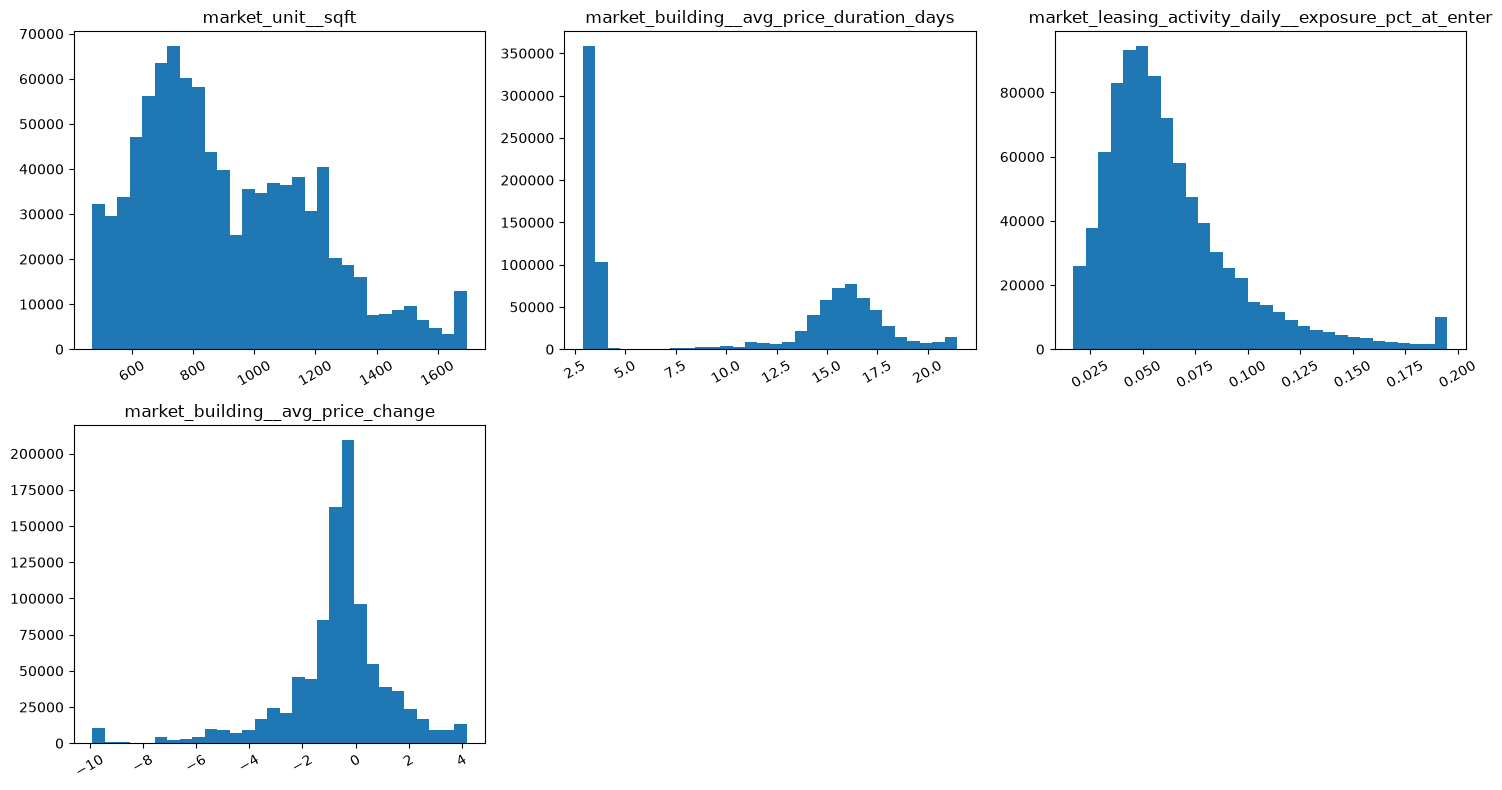


▶ Plotting mean asking rent by feature decile


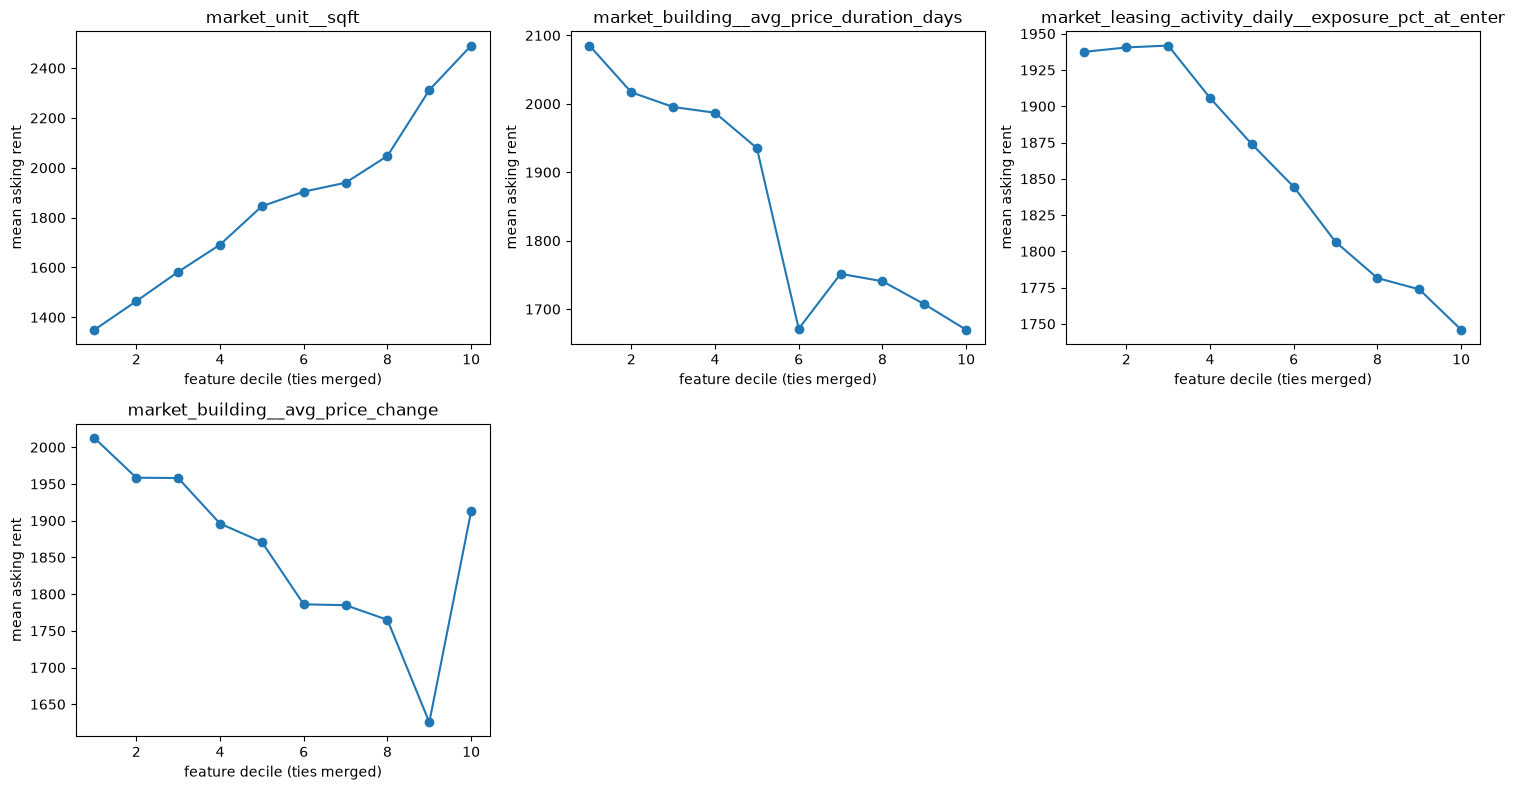

In [5]:
step("Plotting retained feature distributions")
kept_features = final["feature"].tolist()
column_count = 3
row_count = max(1, math.ceil(len(kept_features) / column_count))
figure, axes = plt.subplots(row_count, column_count, figsize=(15, 4 * row_count), squeeze=False)
flat_axes = axes.ravel()
for axis, feature in zip(flat_axes, kept_features):
    values = frame[feature].dropna()
    if not values.empty:
        axis.hist(values.clip(values.quantile(0.01), values.quantile(0.99)), bins=30)
    axis.set_title(feature)
    axis.tick_params(axis="x", labelrotation=30)
for axis in flat_axes[len(kept_features):]:
    axis.remove()
figure.tight_layout()
figure.savefig(out("numerical_histograms", "png"), dpi=150)
plt.show()

step("Plotting mean asking rent by feature decile")
figure, axes = plt.subplots(row_count, column_count, figsize=(15, 4 * row_count), squeeze=False)
flat_axes = axes.ravel()
for axis, feature in zip(flat_axes, kept_features):
    pair = frame[[feature, TARGET]].dropna().copy()
    if len(pair) >= 2 and pair[feature].nunique() >= 2:
        pair["decile"] = pd.qcut(pair[feature], 10, duplicates="drop")
        means = pair.groupby("decile", observed=True)[TARGET].mean()
        axis.plot(range(1, len(means) + 1), means.to_numpy(), marker="o")
    axis.set_title(feature)
    axis.set_xlabel("feature decile (ties merged)")
    axis.set_ylabel("mean asking rent")
for axis in flat_axes[len(kept_features):]:
    axis.remove()
figure.tight_layout()
figure.savefig(out("numerical_target_by_decile", "png"), dpi=150)
plt.show()


In [6]:
step("Suggestion funnel")
counts = [
    len(selection),
    int(is_candidate.sum()),
    int(complete_enough.sum()),
    int((complete_enough & methods_enough).sum()),
    int(selection["suggested"].eq("keep").sum()),
]
labels = ["numerical variables", "candidate", "complete enough", f"≥ {MIN_METHODS} methods", "suggested keep"]
for label, count in zip(labels, counts):
    color = GREEN if count / max(len(selection), 1) >= 0.5 else YELLOW if count else RED
    print(f"  {label:24s}{color}{'█' * round(40 * count / max(len(selection), 1)):40s} {count:>4}{RESET}")

step("Decision counts")
by_user = int(selection["decided_by"].eq("you").sum())
by_suggestion = int(selection["decided_by"].eq("suggested").sum())
kept_count = int(selection["final_decision"].eq("keep").sum())
dropped_count = int(selection["final_decision"].eq("drop").sum())
print(f"  decided by you: {by_user}; by suggestion: {by_suggestion}")
print(f"  kept: {kept_count}; dropped: {dropped_count}")

step("Final numerical feature list")
final = selection[selection["final_decision"].eq("keep")].copy()
for row in final.itertuples():
    print(f"{GREEN}  ✓ {row.feature} [{row.decided_by}]{RESET} gini {row.gini:+.3f}  "
          f"gb {row.gradient_boosting:.4f}  lasso {row.lasso:+.2f}  "
          f"answer-key Gini {row.gini_answer_key:+.3f}")
final[["source_table", "feature", "completeness_pct", "gini", "gradient_boosting",
       "lasso", "gini_answer_key", "n_methods", "redundant_with", "final_decision",
       "decided_by", "note"]]


▶ Suggestion funnel
  numerical variables     ████████████████████████████████████████  108
  candidate               ████████████████                           44
  complete enough         ████████████                               32
  ≥ 2 methods             █                                           4
  suggested keep          █                                           4

▶ Decision counts
  decided by you: 0; by suggestion: 108
  kept: 4; dropped: 104

▶ Final numerical feature list
  ✓ market_unit__sqft [suggested] gini +0.538  gb 0.0021  lasso +0.44  answer-key Gini +0.542
  ✓ market_building__avg_price_duration_days [suggested] gini -0.227  gb 0.0001  lasso -0.12  answer-key Gini -0.227
  ✓ market_leasing_activity_daily__exposure_pct_at_enter [suggested] gini -0.112  gb 0.0000  lasso +0.97  answer-key Gini -0.113
  ✓ market_building__avg_price_change [suggested] gini -0.124  gb 0.0000  lasso -1.45  answer-key Gini -0.126


,source_table,feature,completeness_pct,gini,gradient_boosting,lasso,gini_answer_key,n_methods,redundant_with,final_decision,decided_by,note
5,market_unit,market_unit__sqft,95.67,0.5376,0.0021,0.44,0.5425,3,,keep,suggested,
12,market_building,market_building__avg_price_duration_days,100.00,-0.2267,0.0001,-0.12,-0.2269,2,,keep,suggested,building-level average over the whole history;...
30,market_leasing_activity_daily,market_leasing_activity_daily__exposure_pct_at...,90.49,-0.1115,0.0000,0.97,-0.1125,2,,keep,suggested,
87,market_building,market_building__avg_price_change,100.00,-0.1244,0.0000,-1.45,-0.1261,2,,keep,suggested,building-level average over the whole history;...


## How to read this

These results come from synthetic data, so they check the method and are not a final feature list. As described in `docs/project_phases.md` §2, synthetic data can test recovery of known truth but cannot establish the final feature list or real-world accuracy.

The decision table contains all numerical variables, their scores and correlations, the automatic suggestion,
and the final decision. A filled `my_decision` overrides the suggestion. Edit
`notebooks/phase_01_market_rent/numerical_decisions.csv` with `keep` or `drop` (and an optional comment);
Notebook 05 creates the file if needed and never overwrites it. The profile, city Gini, and plots use only
variables whose `final_decision` is `keep`.